<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/f1_score.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚖️ F1 分數 (F1-Score)

> **一句話記住**：F1 是**精確率和召回率的「綜合成績」**，兩者都要好，F1 才會高。

📚 [回到評估指標總覽](./README.md)

## 🎯 學完這份筆記本，你會…
- 手算與用 `sklearn` 算出 F1
- 理解為什麼 F1 用「**調和平均**」，而不是一般的平均
- 用 `classification_report` 一次看完所有分類指標

---

## 🏫 生活比喻：偏科的學生

| 學生 | 國文（精確率） | 數學（召回率） | 一般平均 | **F1（調和平均）** |
| :--- | :---: | :---: | :---: | :---: |
| 小明（均衡） | 80 | 80 | 80 | **80** |
| 小華（嚴重偏科） | 100 | 10 | 55 | **18** |

一般平均會讓偏科的小華看起來「還可以」；**F1 會嚴格懲罰偏科**，只要有一科很爛，F1 就很低。

## 📐 公式

$$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

**白話讀法**：F1 會被「**比較差的那一個**」往下拉，所以模型不能只靠單一指標刷分。

---
### 【步驟 0】環境準備：載入套件與中文字型

> 這一格只要**按執行**就好，不用看懂。它會幫你安裝中文字型，讓圖表上的中文不會變成 □□□。

In [1]:
# 【步驟 0】載入套件與設定中文字型（Colab / Mac / Windows 通用）
import os, glob, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mplfonts
except ImportError:  # Colab 第一次執行時自動安裝
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mplfonts"])
    import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")

# 統一圖表風格：去掉上、右邊框，讓畫面更乾淨
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "figure.dpi": 100,
})
BLUE, GREEN, RED, ORANGE, PURPLE, GRAY = "#3182ce", "#38a169", "#e53e3e", "#dd6b20", "#805ad5", "#a0aec0"

print("✅ 套件與中文字型載入完成！")

✅ 套件與中文字型載入完成！


---
### 【步驟 1】準備資料：搜尋引擎判斷 10 篇文章是否和關鍵字相關

`1` = 相關、`0` = 不相關

In [2]:
# 學生可以透過 prompt: "定義搜尋結果相關性情境的 y_true 與 y_pred，並計算 TP、FP、FN"
y_true = [1, 0, 1, 0, 1, 0, 1, 0, 0, 1]  # 實際：1=相關
y_pred = [1, 0, 1, 1, 0, 0, 1, 0, 1, 1]  # 模型的判斷

TP = sum((t == 1 and p == 1) for t, p in zip(y_true, y_pred))
FN = sum((t == 1 and p == 0) for t, p in zip(y_true, y_pred))
FP = sum((t == 0 and p == 1) for t, p in zip(y_true, y_pred))
TN = sum((t == 0 and p == 0) for t, p in zip(y_true, y_pred))

print(f"TP={TP}（相關且被找出）, FP={FP}（不相關卻被找出）, FN={FN}（相關卻沒找出）")

TP=4（相關且被找出）, FP=2（不相關卻被找出）, FN=1（相關卻沒找出）


---
### 【步驟 2】先算精確率、召回率，再算 F1

In [3]:
# 學生可以透過 prompt: "手算 Precision、Recall 與 F1（避免除以零），並用 sklearn 的 f1_score 驗證"
from sklearn.metrics import precision_score, recall_score, f1_score

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print(f"精確率 Precision：{TP}/({TP}+{FP}) = {precision:.2f}")
print(f"召回率 Recall   ：{TP}/({TP}+{FN}) = {recall:.2f}")
print(f"一般平均        ：{(precision + recall) / 2:.3f}")
print(f"📝 手算 F1      ：{f1:.3f}")
print(f"🤖 sklearn F1   ：{f1_score(y_true, y_pred):.2f}")

精確率 Precision：4/(4+2) = 0.67
召回率 Recall   ：4/(4+1) = 0.80
一般平均        ：0.733
📝 手算 F1      ：0.727
🤖 sklearn F1   ：0.73


#### 👀 看懂結果
精確率 0.67、召回率 0.80，F1 = **0.727**，一般平均是 0.733。F1 一定落在兩者之間，而且**比一般平均更靠近較低的那一個**。
這裡兩者差不多，是因為精確率和召回率很接近；兩者差距越大，F1 就會被拉得越低（看下一步的圖）。

---
### 【步驟 3】視覺化：為什麼 F1 會「懲罰偏科」？

固定精確率 = 0.9，讓召回率從 0 變到 1，比較「一般平均」和「F1」。

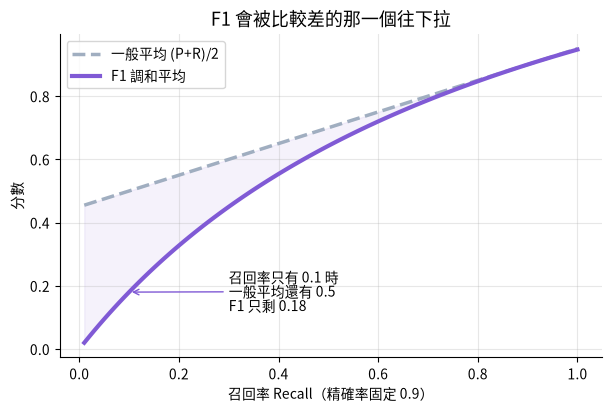

In [4]:
# 學生可以透過 prompt: "固定 precision=0.9，讓 recall 從 0 到 1 變化，畫出算術平均與 F1 的比較折線圖"
p = 0.9
r = np.linspace(0.01, 1, 100)
mean_score = (p + r) / 2
f1_curve = 2 * p * r / (p + r)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(r, mean_score, color=GRAY, lw=2.5, ls="--", label="一般平均 (P+R)/2")
ax.plot(r, f1_curve, color=PURPLE, lw=3, label="F1 調和平均")
ax.fill_between(r, f1_curve, mean_score, color=PURPLE, alpha=0.08)
ax.annotate("召回率只有 0.1 時\n一般平均還有 0.5\nF1 只剩 0.18",
            xy=(0.1, 0.18), xytext=(0.3, 0.12), fontsize=10,
            arrowprops=dict(arrowstyle="->", color=PURPLE))
ax.set_xlabel("召回率 Recall（精確率固定 0.9）")
ax.set_ylabel("分數")
ax.set_title("F1 會被比較差的那一個往下拉")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

---
### 【步驟 4】實務必學：`classification_report` 一次看完全部

實際工作時，不會一個一個算，而是用這個函式一次印出所有指標。

In [5]:
# 學生可以透過 prompt: "使用 sklearn 的 classification_report 印出各類別的 precision、recall、f1-score 與 support"
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=["不相關 (0)", "相關 (1)"], digits=2))

              precision    recall  f1-score   support

     不相關 (0)       0.75      0.60      0.67         5
      相關 (1)       0.67      0.80      0.73         5

    accuracy                           0.70        10
   macro avg       0.71      0.70      0.70        10
weighted avg       0.71      0.70      0.70        10



#### 👀 怎麼看這張報表？

| 欄位 | 意思 |
| :--- | :--- |
| `precision` / `recall` / `f1-score` | 把「這一列的類別」當成正類時算出的指標 |
| `support` | 這一類在實際資料中有幾筆 |
| `accuracy` | 整體準確率 |
| `macro avg` | 各類別指標**直接平均**（每類一樣重要） |
| `weighted avg` | 依照 `support` 加權平均（筆數多的類別比重大） |

我們剛剛手算的是「**相關 (1)**」那一列：precision 0.67、recall 0.80、f1 0.73 ✅

---
## 🧭 什麼時候用 F1？

- 精確率和召回率**都很重要**，不想偏重任何一邊
- 資料**不平衡**，準確率不可靠時（例如：詐騙偵測、罕見疾病）
- 需要用**一個數字**比較多個模型

---
## ⚠️ 常見誤區

| 誤區 | 正確觀念 |
| :--- | :--- |
| F1 = 精確率和召回率的平均 | 是「**調和**平均」，會被較差的一方拉低。 |
| F1 永遠是最好的指標 | 如果明確知道「漏報」比較嚴重，就直接看召回率。 |

---
## ✍️ 隨堂練習

**練習**：模型 A 精確率 0.9、召回率 0.3；模型 B 精確率 0.6、召回率 0.6。哪個 F1 比較高？

<details>
<summary>💡 點我看答案</summary>

- 模型 A：F1 = 2 × 0.9 × 0.3 ÷ (0.9 + 0.3) = 0.54 ÷ 1.2 = **0.45**
- 模型 B：F1 = 2 × 0.6 × 0.6 ÷ 1.2 = **0.60**

雖然 A 的一般平均也是 0.6，但 F1 選擇了比較**均衡**的模型 B。

</details>

---
## 📝 重點回顧

| 重點 | 內容 |
| :--- | :--- |
| 意義 | 精確率與召回率的綜合成績 |
| 公式 | 2 × P × R ÷ (P + R) |
| sklearn | `f1_score(y_true, y_pred)`、`classification_report(...)` |
| 特色 | 嚴格懲罰「偏科」 |
| 下一步 | 👉 [AUC-ROC 曲線](./auc_roc_curve.ipynb) |

## 🤖 問問 AI
> 「classification_report 裡的 macro avg 和 weighted avg 差在哪裡？在資料不平衡時應該看哪一個？」